## PyTorchのRNNを検算してみる

In [1]:
import torch
from torch import nn

In [2]:
input_dim = 3
hidden_dim = 4
model = nn.RNN(
    input_size = input_dim,
    hidden_size = hidden_dim,
)

In [3]:
model

RNN(3, 4)

In [4]:
from pprint import pprint

In [5]:
pprint(list(model.named_parameters()))

[('weight_ih_l0',
  Parameter containing:
tensor([[ 0.1182,  0.1812, -0.2387],
        [-0.3265, -0.2232, -0.3603],
        [ 0.0829, -0.4934,  0.4242],
        [ 0.3093, -0.2689,  0.0967]], requires_grad=True)),
 ('weight_hh_l0',
  Parameter containing:
tensor([[-0.3120,  0.4372, -0.4493,  0.1183],
        [ 0.1549, -0.2532, -0.1203, -0.2204],
        [-0.0656,  0.3983, -0.1754, -0.2151],
        [-0.1868,  0.0288, -0.2995, -0.4942]], requires_grad=True)),
 ('bias_ih_l0',
  Parameter containing:
tensor([ 0.4475, -0.1179, -0.0883,  0.0712], requires_grad=True)),
 ('bias_hh_l0',
  Parameter containing:
tensor([ 0.1494,  0.4368, -0.0349,  0.2779], requires_grad=True))]


In [6]:
T = 5 # 入力する系列の長さ
batch_size = 2 # 一度に処理するデータの数
X = torch.randn(T, batch_size, input_dim) # ダミーの入力データ

In [7]:
X

tensor([[[-0.0341, -0.8434, -0.1612],
         [ 1.3640,  0.0556,  0.2345]],

        [[-2.0439,  0.9547, -0.9245],
         [ 0.6876,  1.0400,  0.4263]],

        [[ 0.1257,  0.6922,  0.0827],
         [-0.4845,  0.3465,  1.5043]],

        [[ 1.2888, -0.1444, -0.1686],
         [-0.8146, -0.7632,  0.5683]],

        [[-1.3022,  0.4096,  0.0203],
         [-1.0393,  0.4576, -0.2407]]])

In [8]:
H, hn = model(X)

In [9]:
H.shape

torch.Size([5, 2, 4])

In [10]:
H

tensor([[[ 0.4451,  0.5200,  0.2182,  0.5004],
         [ 0.6121, -0.2198,  0.0618,  0.6520]],

        [[ 0.6633,  0.7197, -0.8088, -0.7658],
         [ 0.4832, -0.2840, -0.5897, -0.1372]],

        [[ 0.7998,  0.2730,  0.1298,  0.6214],
         [ 0.2138,  0.1052,  0.2840,  0.3779]],

        [[ 0.5706, -0.1063, -0.1163,  0.2754],
         [ 0.1225,  0.4132,  0.3128,  0.0487]],

        [[ 0.3564,  0.6131, -0.4954, -0.3564],
         [ 0.5526,  0.4690, -0.4186, -0.2424]]], grad_fn=<StackBackward0>)

In [11]:
hn

tensor([[[ 0.3564,  0.6131, -0.4954, -0.3564],
         [ 0.5526,  0.4690, -0.4186, -0.2424]]], grad_fn=<StackBackward0>)

## サイン波の予測

In [1]:
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import json
import h5py
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


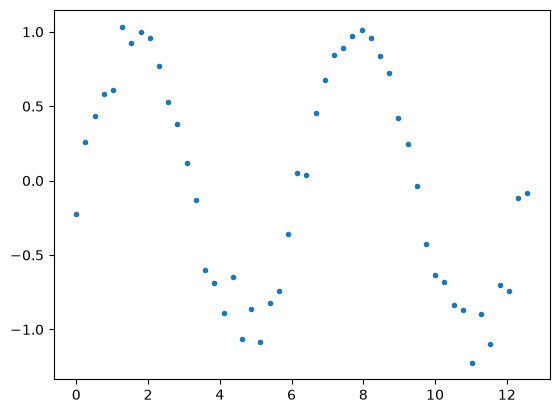

In [6]:
def generate_train_data():


    # 訓練データ
    x = np.linspace(0, 4*np.pi, 50)
    rng = np.random.default_rng(seed = 2025)
    sin_x = np.sin(x) + rng.normal(0, 0.1, len(x))

    fig,ax = plt.subplots()

    ax.plot(x,sin_x,
            lw = 0,
            marker = ".",)

    return {"x": x, "y": sin_x}
TrainingData = generate_train_data()
del generate_train_data

In [7]:
# ハイパーパラメータ
hyper_parameter = {}
hyper_parameter["n_time"] = 10 # 10個の時系列を1セット
hyper_parameter["n_sample"] = len(TrainingData["x"]) - hyper_parameter["n_time"] # 40
print(json.dumps(hyper_parameter, indent = 4))

{
    "n_time": 10,
    "n_sample": 40
}


In [18]:
# 前処理
def process_data(data, parameter):
    ## 空の配列を準備
    input_data = np.zeros((parameter["n_sample"], parameter["n_time"], 1))
    correct_data = np.zeros((parameter["n_sample"], 1))

    ## 配列にTrainDataを格納
    for i in tqdm(range(parameter["n_sample"])):
        input_data[i] = data["y"][i:i+parameter["n_time"]].reshape(-1,1)
        correct_data[i] = [data["y"][i+parameter["n_time"]]]
    input_data = torch.FloatTensor(input_data)
    correct_data = torch.FloatTensor(correct_data)

    # ## バッチデータの準備
    dataset = TensorDataset(input_data, correct_data)
    train_loader = DataLoader(dataset, batch_size=8, shuffle=True)
    return dataset, train_loader
dataset, train_loader = process_data(data = TrainingData, parameter = hyper_parameter)

100%|██████████| 40/40 [00:00<00:00, 73071.50it/s]


In [19]:
# モデルの定義
class RNN(nn.Module):
    def __init__(self): # コンストラクタを定義
        super(RNN, self).__init__()
        self.rnn = nn.RNN(1, 64, batch_first=True) # RNNのモジュール（入力1、隠れ層64）
        self.fc = nn.Linear(64, 1) # 全結合層（入力64、出力1）
    def forward(self, x):
        batch_size = x.size(0) # 入力の行数をバッチサイズに設定
        x = x.to(device) # 処理をGPUに移行
        x_rnn, hidden = self.rnn(x, None) # ?
        x = self.fc(x_rnn[:, -1, :])
        return x

model = RNN().to(device)
criterion = nn.MSELoss() # 平均二乗誤差
optimizer = optim.SGD(model.parameters(), lr=0.01) # 確率的勾配降下法

In [ ]:
record_loss_train = []
len_epoch = 201

for i in range(len_epoch):
    model.train() # 訓練モード
    loss_train = 0
    for j, (x, t) in enumerate(train_loader):
        loss = criterion(model(x), t.to(device))
        loss_train += loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    loss_train /= j+1
    record_loss_train.append(loss_train)

    if i%20 == 0:
        print("Epoch: {}, Loss_Train: {}".format(i, loss_train))
        predict = list(dataset.values)

In [ ]:

record_loss_train = [] # 誤差(loss)を記録する空の配列を用意

for i in range(201):
  model.train() # 訓練モード
  loss_train = 0
  for j, (x, t) in enumerate(train_loader):
      loss = criterion(model(x), t.to(device))
      loss_train += loss.item()
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
  loss_train /= j+1
  record_loss_train.append(loss_train)
  if i%20 == 0:
      print("Epoch:", i, "Loss_Train:", loss_train)
      predicted = list(input_data[0].reshape(-1)) # 最初のシーケンスを予測の初期値として設定する
      model.eval()
      with torch.no_grad(): # 勾配計算をしないことによって処理速度を上げる
          for i in range(n_sample):
            x = torch.tensor(predicted[-n_time:])
            x = x.reshape(1, n_time, 1)
            predicted.append(model(x)[0].item())
      plt.plot(range(len(sin_x)), sin_x, label="Correct")
      plt.plot(range(len(predicted)), predicted, label="Predicted")
      plt.legend()
      plt.show()

初めの誤差： 45.95 %
最終誤差　： 10.76  %


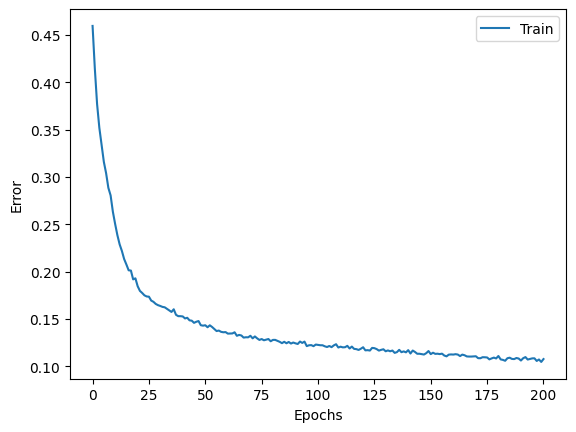

In [ ]:
'''精度の確認'''
print('初めの誤差：', round(record_loss_train[0]*100,2), '%')
print('最終誤差　：', round(record_loss_train[-1]*100,2), ' %')
plt.plot(range(len(record_loss_train)), record_loss_train, label='Train')
plt.legend()
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.show()